In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

housing = pd.read_csv('housing.csv')
print(housing.shape)
print(housing.isnull().sum())
housing.head()

(20640, 10)
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 1. Explore the data

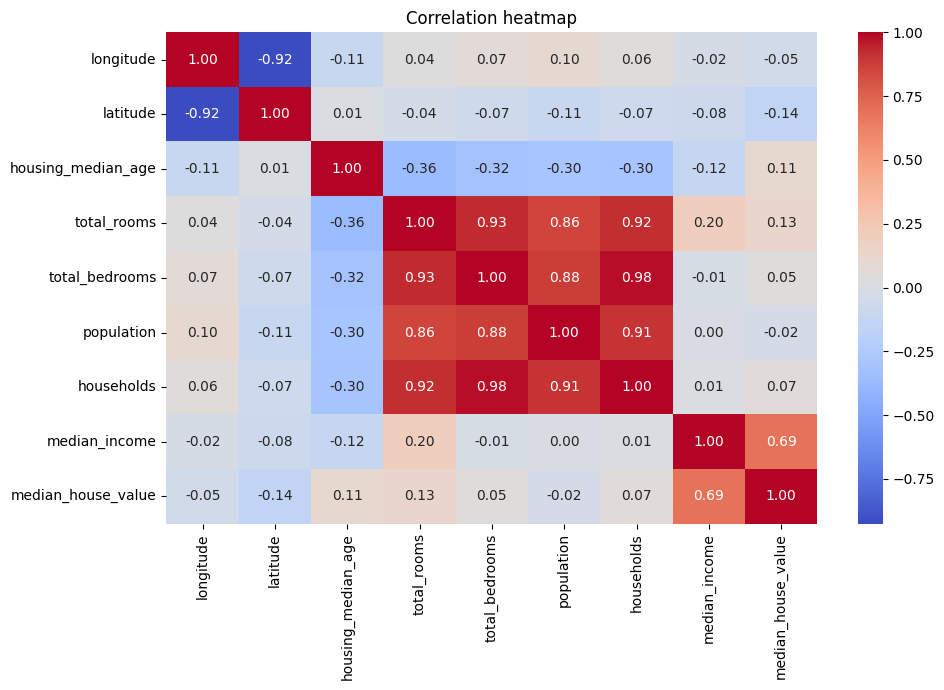

In [2]:
plt.figure(figsize=(10, 7))
sns.heatmap(housing.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap')
plt.tight_layout()
plt.show()

## 2.features


In [3]:
housing['rooms_per_household'] = housing['total_rooms'] / housing['households']
housing['bedrooms_per_room'] = housing['total_bedrooms'] / housing['total_rooms']
housing['population_per_household'] = housing['population'] / housing['households']
housing['income_x_rooms'] = housing['median_income'] * housing['rooms_per_household']

# Replace any invalid values from division
housing = housing.replace([np.inf, -np.inf], np.nan)

X = housing.drop('median_house_value', axis=1)
y = housing['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = ['ocean_proximity']

num_steps = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_steps = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocess = ColumnTransformer([
    ('num', num_steps, num_cols),
    ('cat', cat_steps, cat_cols)
])

## 3. Train and tune the models
Ridge and Lasso penalize large coefficients, which helps when predictors are correlated. We use cross-validation to select alpha.

In [4]:
models = {
    'OLS': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(max_iter=20000)
}

results = []
predictions = {}
best_models = {}

for name, model in models.items():
    pipe = Pipeline([('preprocess', preprocess), ('model', model)])

    if name == 'OLS':
        pipe.fit(X_train, y_train)
        best_model = pipe
        alpha = '-'
    else:
        search = GridSearchCV(
            pipe,
            {'model__alpha': [0.1, 1, 10, 100, 1000]},
            cv=3, scoring='neg_root_mean_squared_error', n_jobs=-1
        )
        search.fit(X_train, y_train)
        best_model = search.best_estimator_
        alpha = search.best_params_['model__alpha']

    pred = best_model.predict(X_test)
    predictions[name] = pred
    best_models[name] = best_model
    results.append({
        'Model': name,
        'Best alpha': alpha,
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'MAE': mean_absolute_error(y_test, pred),
        'R2': r2_score(y_test, pred)
    })

scores = pd.DataFrame(results).sort_values('RMSE')
print(scores.round(3).to_string(index=False))

Model Best alpha      RMSE       MAE    R2
  OLS          - 68917.317 49709.540 0.638
Ridge        0.1 68918.221 49710.305 0.638
Lasso        100 69003.131 49691.692 0.637


/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.334e+11, tolerance: 1.465e+10
  model = cd_fast.enet_coordinate_descent(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.377e+11, tolerance: 1.465e+10
  model = cd_fast.enet_coordinate_descent(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.521e+11, tolerance: 1.4

## 4. Compare predictions and residuals

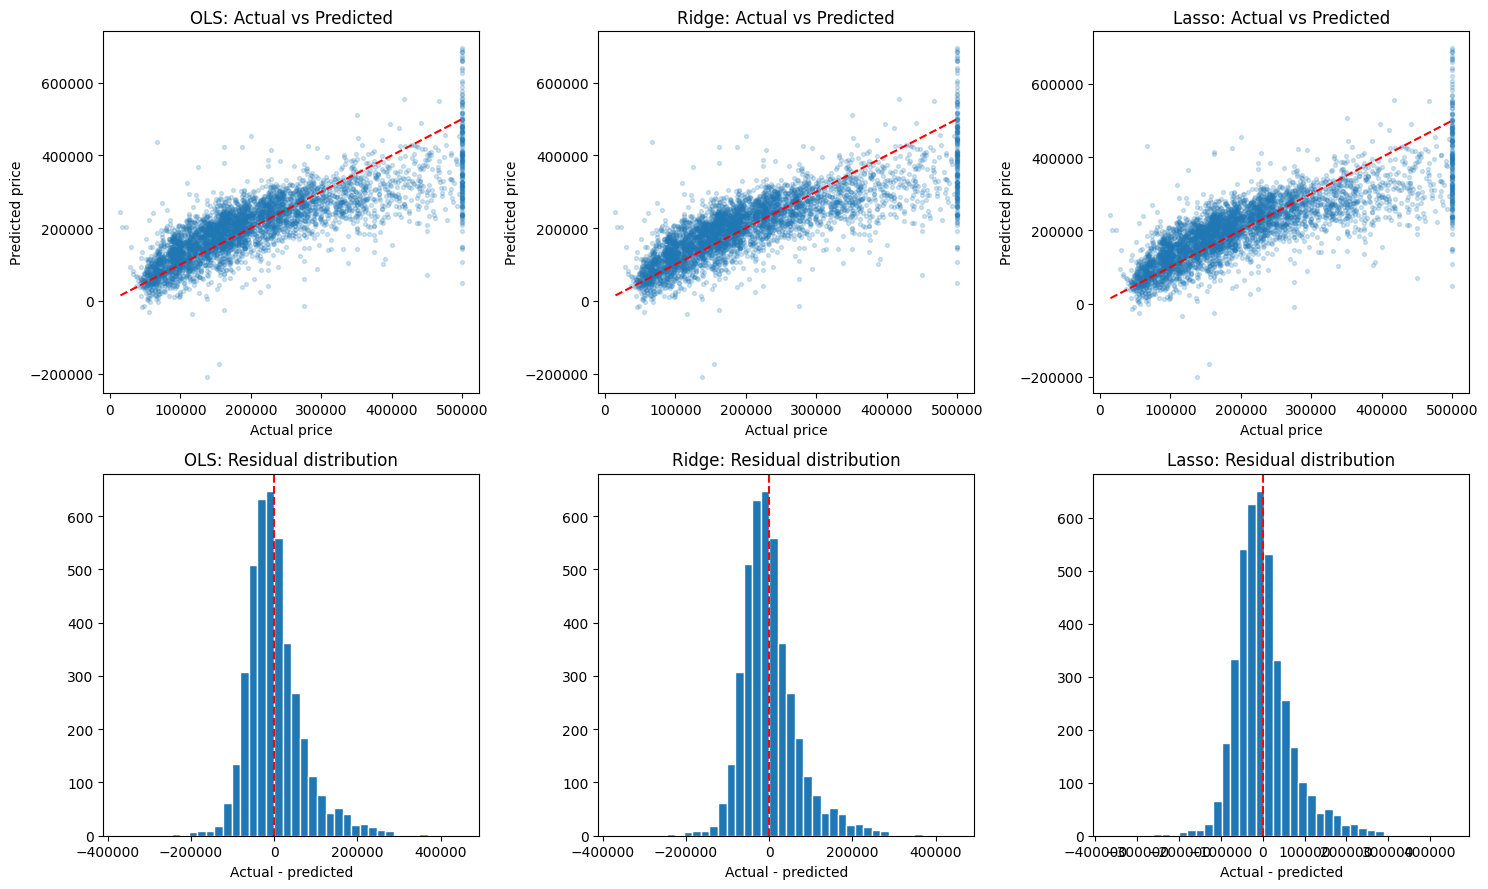

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for i, name in enumerate(models):
    pred = predictions[name]
    residual = y_test - pred
    axes[0, i].scatter(y_test, pred, alpha=0.2, s=8)
    axes[0, i].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    axes[0, i].set_title(name + ': Actual vs Predicted')
    axes[0, i].set_xlabel('Actual price')
    axes[0, i].set_ylabel('Predicted price')
    axes[1, i].hist(residual, bins=40, edgecolor='white')
    axes[1, i].axvline(0, color='red', linestyle='--')
    axes[1, i].set_title(name + ': Residual distribution')
    axes[1, i].set_xlabel('Actual - predicted')
plt.tight_layout()
plt.show()

## 5. Final result

In [6]:
winner = scores.iloc[0]['Model']
print('Best model based on test RMSE:', winner)
print('Lower RMSE and MAE are better; higher R2 is better.')
print('Residuals should ideally be centered around zero.')
print('Ridge and Lasso reduce the effect of multicollinearity through regularization.')

Best model based on test RMSE: OLS
Lower RMSE and MAE are better; higher R2 is better.
Residuals should ideally be centered around zero.
Ridge and Lasso reduce the effect of multicollinearity through regularization.
